In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter
from matplotlib.ticker import EngFormatter
from scipy.signal import welch
from pathlib import Path
import json

def load(filename):
    df = pd.read_csv(filename, header=None,names=['time', 'voltage'])
    df['time'] = pd.to_datetime(df['time'], utc=True,format='ISO8601')
    v = df.set_index('time')['voltage']
    duration = (v.index[-1] - v.index[0]).total_seconds()
    sps = (len(v)-1) / duration
    print(filename)
    print(f'Readings: {len(df)}, duration: {duration/3600:.3f} h')
    print(f'Average output rate: {sps:.8f} SPS')
    return v, sps

f1, mf1 = load('shorted/8588A_10V_20261124-163406.csv')
f1long, mf1long = load('shorted/8588A_10V_20261124-095919.csv')
f10, mf10 = load('shorted/8588A_10V_20261125-074409.csv')
k10, mk10 = load('shorted/3458B_10V_20261125-074419_10NPLC_AZ1_shorted.csv')
f100, mf100 = load('shorted/8588A_10V_20261124-211744.csv')
k100, mk100 = load('shorted/3458B_10V_20261124-215745_100NPLC_AZ1_shorted.csv')
k1, k1_sps = load('shorted/3458B_short_10V_1NPLC_az_on_20251028-225722.csv')

shorted/8588A_10V_20261124-163406.csv
Readings: 216000, duration: 3.000 h
Average output rate: 20.00000000 SPS
shorted/8588A_10V_20261124-095919.csv
Readings: 432000, duration: 6.000 h
Average output rate: 20.00000000 SPS
shorted/8588A_10V_20261125-074409.csv
Readings: 21600, duration: 3.000 h
Average output rate: 2.00000000 SPS
shorted/3458B_10V_20261125-074419_10NPLC_AZ1_shorted.csv
Readings: 21600, duration: 3.000 h
Average output rate: 2.00000000 SPS
shorted/8588A_10V_20261124-211744.csv
Readings: 7000, duration: 9.721 h
Average output rate: 0.20000000 SPS
shorted/3458B_10V_20261124-215745_100NPLC_AZ1_shorted.csv
Readings: 6480, duration: 8.999 h
Average output rate: 0.20000000 SPS
shorted/3458B_short_10V_1NPLC_az_on_20251028-225722.csv
Readings: 748810, duration: 8.807 h
Average output rate: 23.61732205 SPS


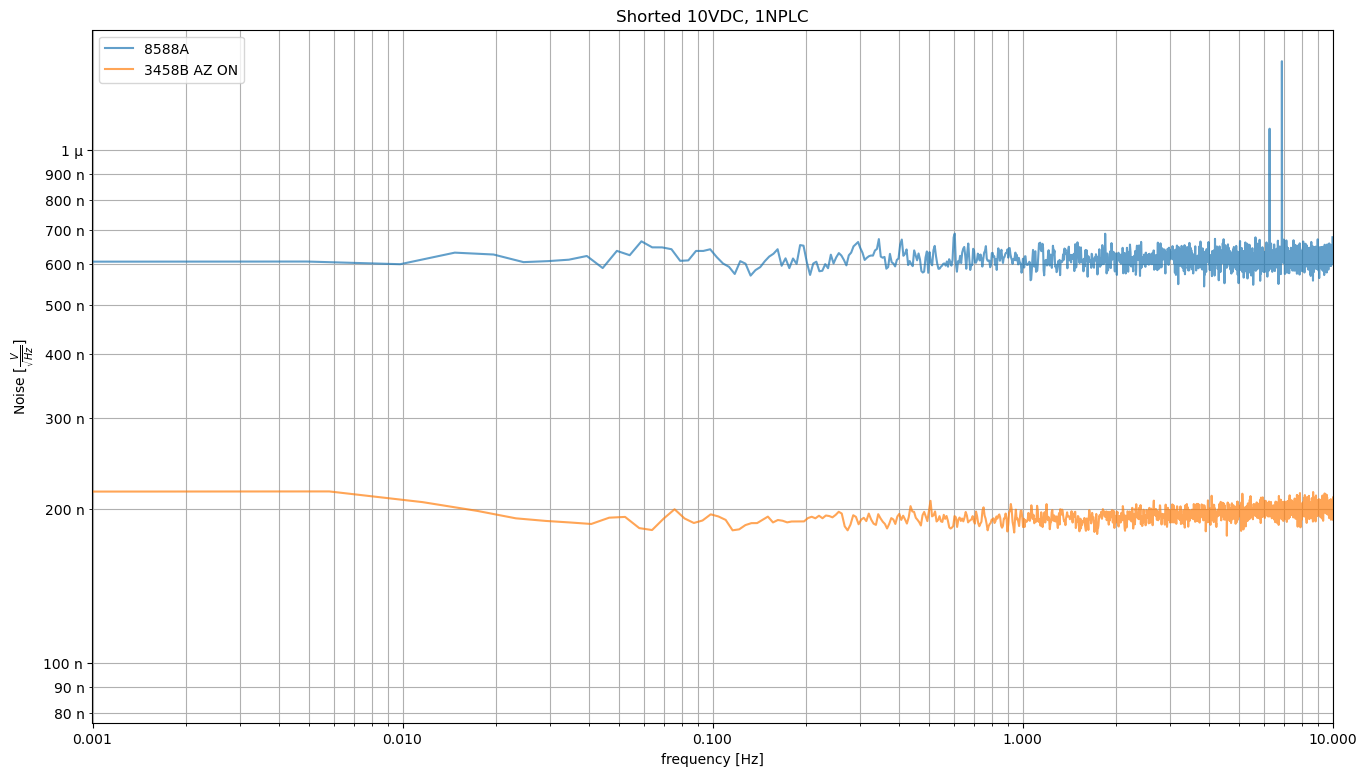

In [ ]:
def process(v, sps, nfft, meter_name):
    f, psd = welch(v.to_numpy(), fs=sps, window='hann', nperseg=nfft, noverlap=nfft//2)
    plt.plot(f, np.sqrt(psd), label=meter_name, alpha=0.7)
    band = (f >= sps*0.1) & (f <= sps*0.45)
    noise = np.sqrt(np.mean(psd[band]))
    return noise

# Set up plot
fig,ax = plt.subplots(figsize=(16,9))
plt.loglog()
plt.xlim([0.001,10])
plt.xlabel('frequency [Hz]')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
plt.ylabel(r'Noise [$\frac{V}{\sqrt{Hz}}$]')
plt.grid(True, which="both")

process(f1long,20,4069,'8588A')
process(k1,k1_sps,4069,'3458B AZ ON')

plt.title('Shorted 10VDC, 1NPLC')
plt.legend()
plt.show()

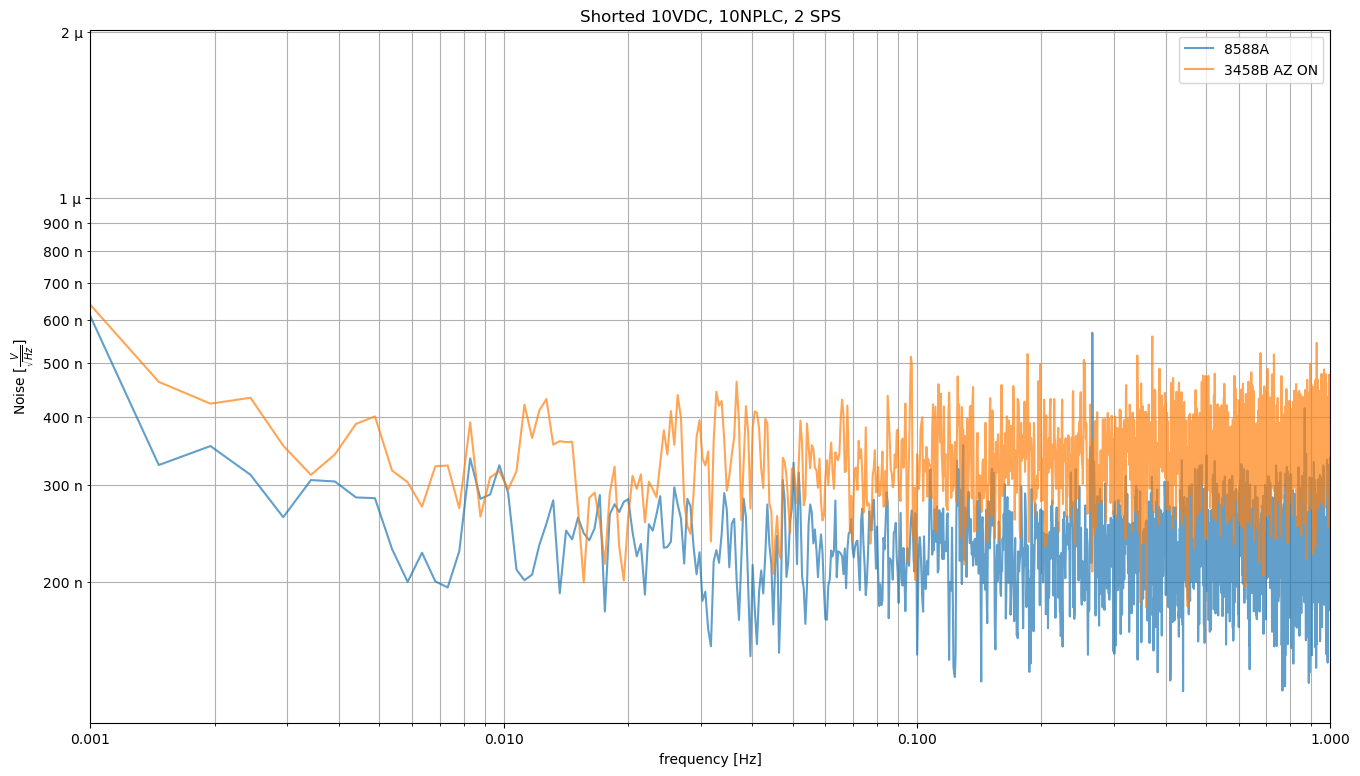

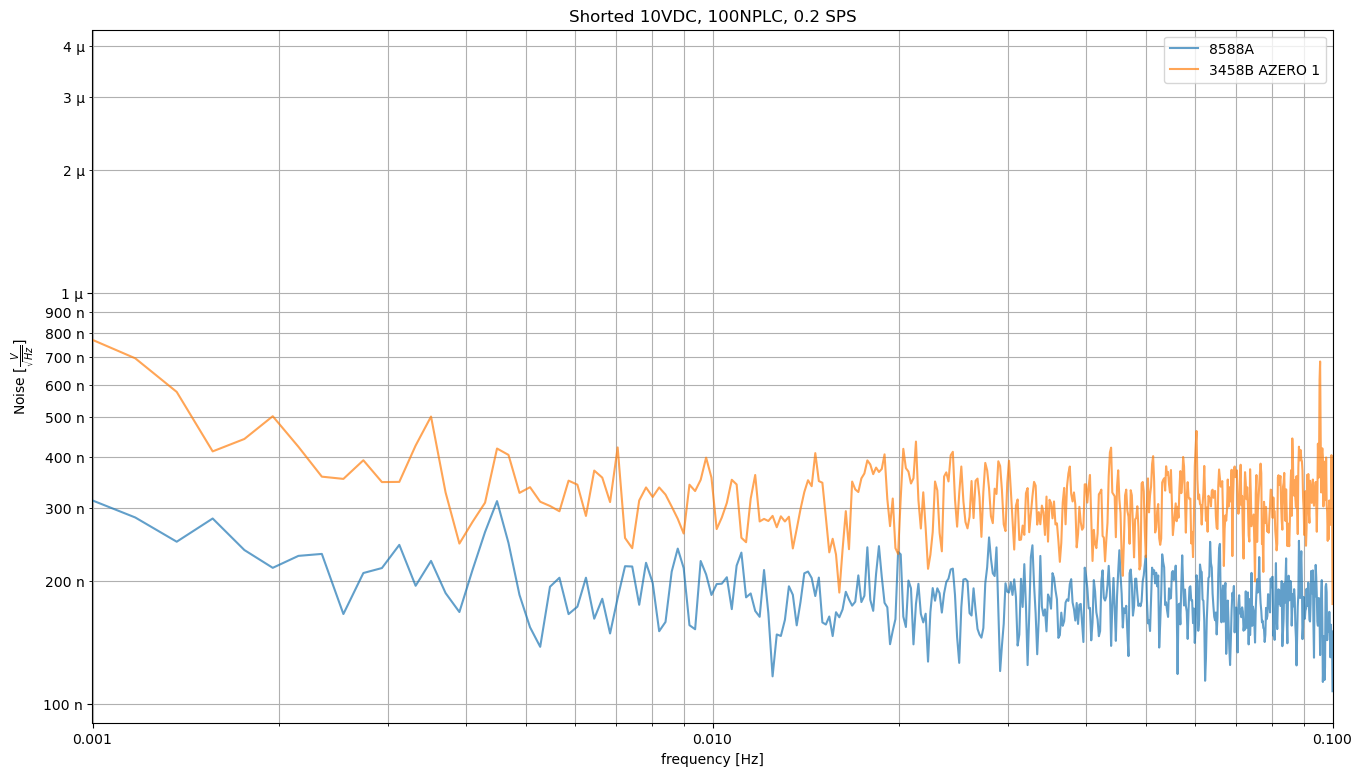

In [ ]:
def process(v, sps, nfft, meter_name):
    f, psd = welch(v.to_numpy(), fs=sps, window='hann', nperseg=nfft, noverlap=nfft//2)
    plt.plot(f, np.sqrt(psd), label=meter_name, alpha=0.7)
    band = (f >= sps*0.1) & (f <= sps*0.45)
    noise = np.sqrt(np.mean(psd[band]))
    return noise

# Set up plot
fig,ax = plt.subplots(figsize=(16,9))
plt.loglog()
plt.xlim([0.001,1])
plt.xlabel('frequency [Hz]')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
plt.ylabel(r'Noise [$\frac{V}{\sqrt{Hz}}$]')
plt.grid(True, which="both")

process(f10, 2, 4096, '8588A')
process(k10, 2, 4096, '3458B AZ ON')

plt.title('Shorted 10VDC, 10NPLC, 2 SPS')
plt.legend()
plt.show()

# Set up plot
fig,ax = plt.subplots(figsize=(16,9))
plt.loglog()
plt.xlim([0.001,0.1])
plt.xlabel('frequency [Hz]')
ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
plt.ylabel(r'Noise [$\frac{V}{\sqrt{Hz}}$]')
plt.grid(True, which="both")

process(f100, 0.2, 1024, '8588A')
process(k100, 0.2, 1024, '3458B AZERO 1')

plt.title('Shorted 10VDC, 100NPLC, 0.2 SPS')
plt.legend()
plt.show()

8588A 10NPLC: min 21.1080211550748 nV at 112.5 s
3458B 10NPLC AZERO 1: min 23.902444401857768 nV at 155.5 s
8588A 100NPLC: min 14.451116187823922 nV at 165 s
3458B 100NPLC AZERO 1: min 25.916755990260835 nV at 150 s
3458B 1NPLC AZERO 1 (2025): min 22.464413056601245 nV at 66.30726365144649 s


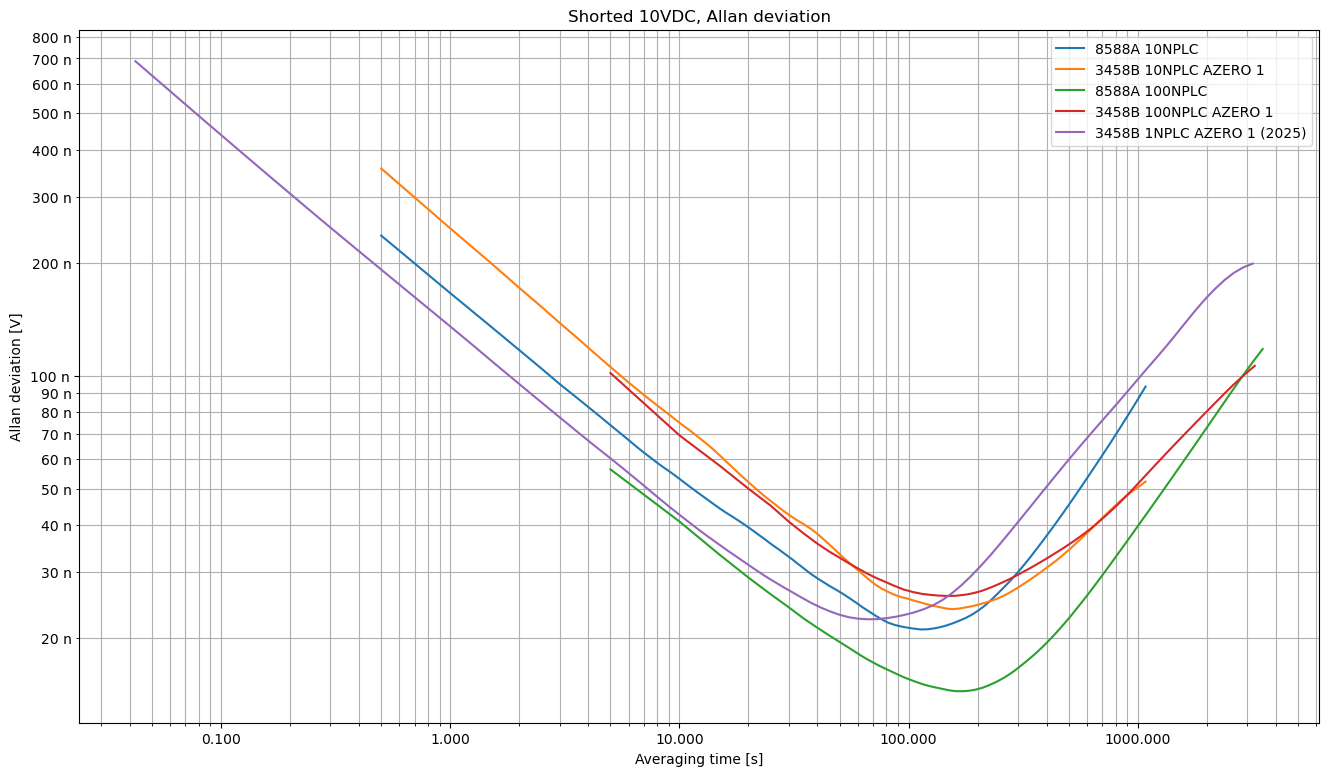

In [ ]:
# Overlapping Allan deviation without detrending
def allan(v, period):
    m_values = np.unique(np.logspace(0, np.log10(len(v)//10), 120).astype(int))
    sums = np.r_[0, np.cumsum(v-v.mean())]
    adev = []
    for m in m_values:
        avg = (sums[m:]-sums[:-m])/m
        adev.append(np.sqrt(np.mean((avg[m:]-avg[:-m])**2)/2))
    return m_values*period, np.array(adev)

def plot_allan(v, period, meter_name):
    t, a = allan(v, period)
    plt.loglog(t, a, label=meter_name)
    i = np.argmin(a)
    print(f'{meter_name}: min {a[i]*1e9} nV at {t[i]} s')

fig, ax = plt.subplots(figsize=(16,9))
plt.title('Shorted 10VDC, Allan deviation')
plot_allan(f10, 0.5, '8588A 10NPLC')
plot_allan(k10, 0.5, '3458B 10NPLC AZERO 1')
plot_allan(f100, 5, '8588A 100NPLC')
plot_allan(k100, 5, '3458B 100NPLC AZERO 1')
plot_allan(k1, 1/k1_sps, '3458B 1NPLC AZERO 1 (2025)')
plt.xlabel('Averaging time [s]')
plt.ylabel('Allan deviation [V]')
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
plt.grid(True, which='both')
plt.legend()
plt.show()

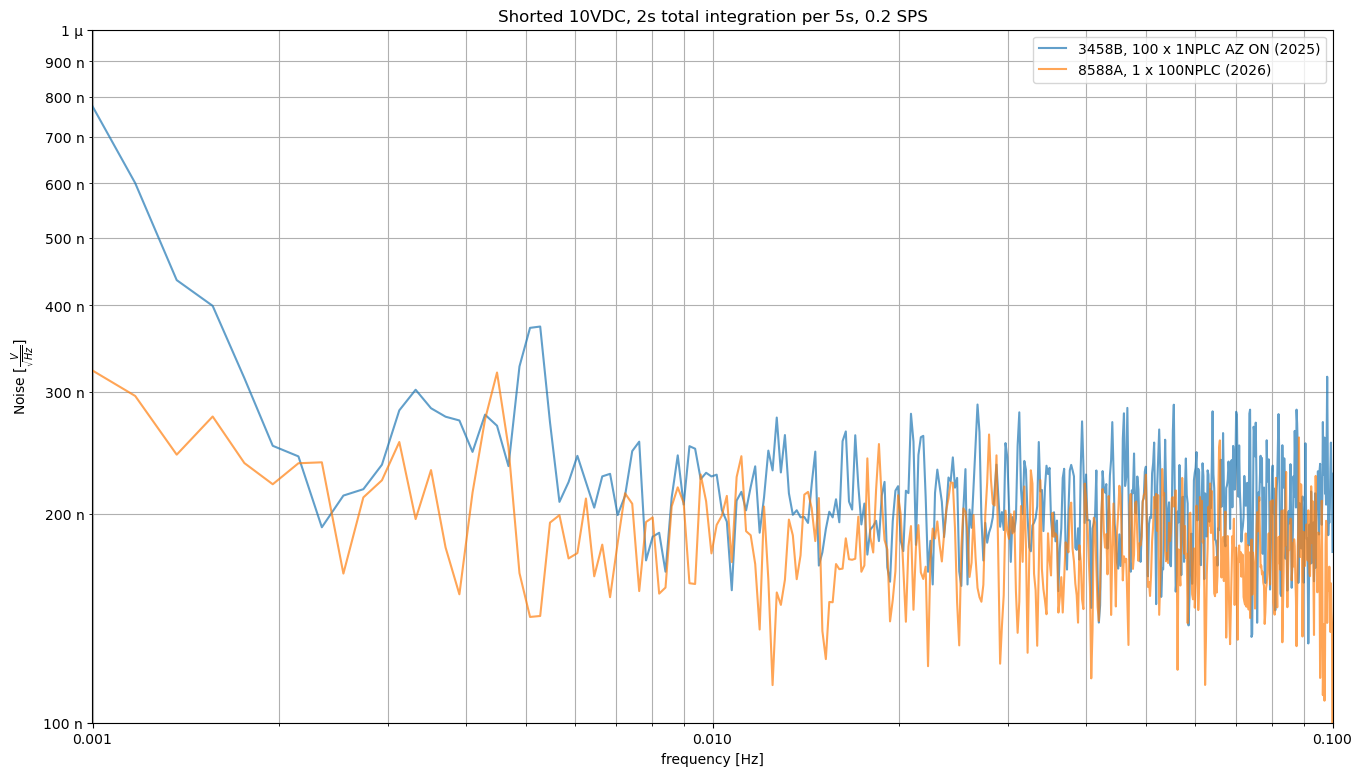

In [ ]:
# Best achievable shorted-input results at 0.2 SPS: 100 x 1NPLC versus 1 x 100NPLC

# Take 100 evenly spaced samples from each 5-second interval (2s total integration).
def average100(block):
    return block.to_numpy()[np.linspace(0, len(block)-1, 100, dtype=int)].mean()

k_best = k1.resample('5s', origin=k1.index[0]).apply(average100).dropna()
n = min(len(k_best), len(f100))
k_best, f_best = k_best.iloc[:n], f100.iloc[:n]

fig, ax = plt.subplots(figsize=(16,9))
plt.loglog()
for v, label in [(k_best, '3458B, 100 x 1NPLC AZ ON (2025)'),
                 (f_best, '8588A, 1 x 100NPLC (2026)')]:
    f, psd = welch(v.to_numpy(), fs=0.2, nperseg=1024, noverlap=512)
    plt.plot(f[1:], np.sqrt(psd[1:]), label=label, alpha=0.7)
plt.xlim([0.001, 0.1])
plt.ylim([1e-7, 1e-6])
plt.xlabel('frequency [Hz]')
plt.ylabel(r'Noise [$\frac{V}{\sqrt{Hz}}$]')
ax.yaxis.set_major_formatter(EngFormatter())
ax.yaxis.set_minor_formatter(EngFormatter())
ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
plt.grid(True, which='both')
plt.title('Shorted 10VDC, 2s total integration per 5s, 0.2 SPS')
plt.legend()
plt.show()